# 图片扩展｜把 Fashion 图片组织成序列

这是 RNN 的选做迁移实验。主课堂先完成[文本情感分类](../06_text_classification/00_情感分类体验.ipynb)；本页用已经学过的图片数据解释“读取方式怎样改变序列”，不要求文本、图片两套作业同时完成。

文本本身具有先后顺序，图片的逐行或分块顺序则由我们规定。本任务不是预测未来图片，也不能证明 RNN 比 CNN 更适合图像。先观察下面的空间对应图，再完成路径、读图、转换和 forward 的关键 TODO。

> **课堂预览**　本页的图是 2026-10-17 的本地 CPU 运行快照，重新执行会更新；人工图解与训练结果已分别标明。只阅读可直接展开输出，实验时仍需从第一格执行。作业只保留 TODO 之前的预览，没有填入答案或作业训练成绩。

In [1]:
from pathlib import Path
import sys, json
from datetime import datetime
from uuid import uuid4
import numpy as np
import torch
from torch import nn
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# 支持仓库根目录、03_rnn_lab、任务目录，以及它们的下级工作目录。
LAB_DIR = None
for directory in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    for candidate in (directory, directory / "03_rnn_lab"):
        if (candidate / "rnn_lab").is_dir() and (candidate / "README.md").is_file():
            LAB_DIR = candidate
            break
    if LAB_DIR is not None:
        break
if LAB_DIR is None:
    raise FileNotFoundError("请从完整课程仓库、03_rnn_lab 或图片任务目录运行。")
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))
from rnn_lab import (
    ExperimentConfig, SequenceDatasetBundle, seed_everything, run_experiment,
    evaluate_final, experiment_records, export_experiments_csv,
    observe_recurrence, print_model_summary, plot_recurrent_trace,
    plot_training_history, configure_chinese_font,
)
from rnn_lab.image_tasks import (
    DATA_VERSION, prepare_fashion_archive, check_image_split, check_rows, check_patches,
)
torch.set_num_threads(1)
configure_chinese_font()
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f") + "_" + uuid4().hex[:8]
OUTPUT_DIR = LAB_DIR / "outputs" / "05_image_classification" / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("本轮新输出：", OUTPUT_DIR)
def save_figure(fig, name):
    path = OUTPUT_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("已保存：", path)
    return path

本轮新输出： <实验室目录>\outputs\05_image_classification\20261017_134234_425989_745da9d2


## 先看见一条时间步究竟覆盖哪里

下面是教师编号矩阵，仅讲空间对应；实际训练仍使用原 Fashion 数据。中图橙色是一整行，右图橙框是一个 2×2 块。每步包含的信息变了，所以 T 和 F 同时变化。

请先手写橙色区域的数，再确定读取顺序。方形图片交换高宽后 shape 可能仍对，因此作业还要检查非方形、多样本和指定坐标。本图不提供转换函数答案。

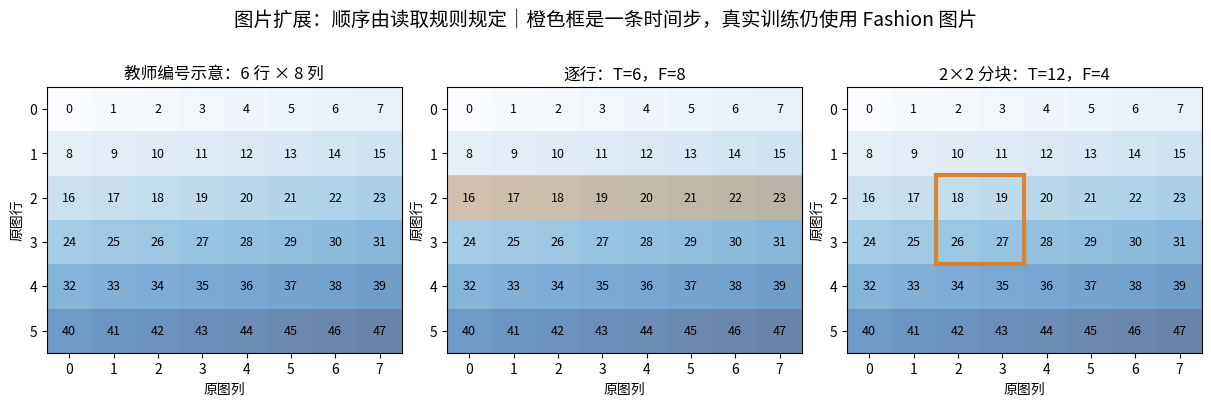

In [2]:
from rnn_lab.teaching_visuals import plot_image_sequence_preview
import matplotlib.pyplot as plt

fig = plot_image_sequence_preview()
plt.show()
plt.close(fig)

## 把图片作为扩展练习时，选择一个目标

基础先跑通完整流程；B 比较循环单元，C 在 B 上改变读出，D 在 B 上改变空间组织，E 只对照 A 检查手写实现。每次比较说明改变了什么，别把输入维度变化全部解释成记忆能力。

下面仍保留全部学生 TODO。先看图再动手，不能用预览结果替代自己的运行记录。

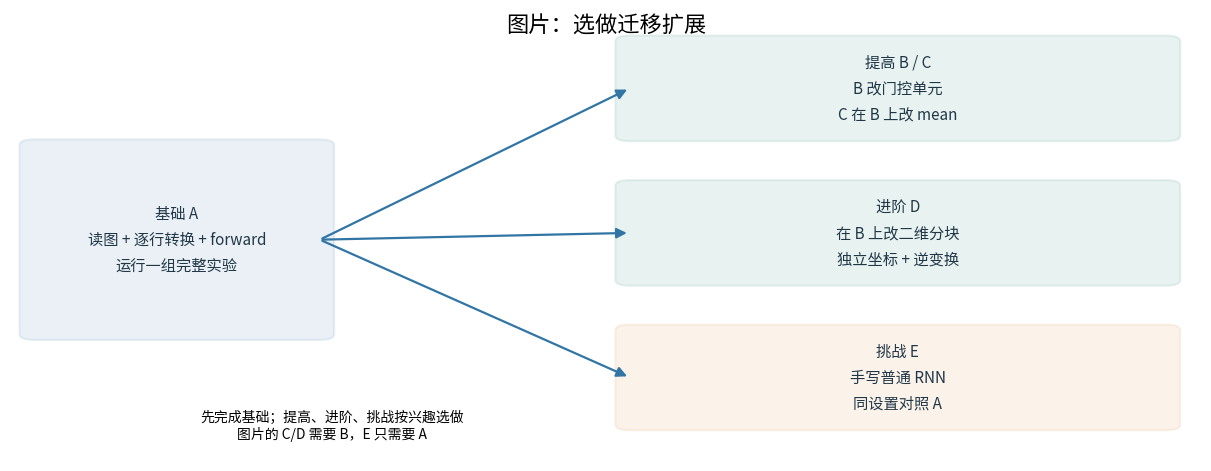

In [3]:
from rnn_lab.teaching_visuals import plot_assignment_route
import matplotlib.pyplot as plt

fig = plot_assignment_route("image")
plt.show()
plt.close(fig)

## 0｜先预测，再确定统一条件

沿用 CNN 既有离线 Fashion 包：bag、sneaker、trousers；实际 900/300/300 张，保留原 train/val/test 身份，不下载、不另造数据。类别数从映射表推导。数据包核验与 SHA256 见[本目录 README](README.md)。

同一正式预算与 seed 下比较，记录实际参数量与耗时。B/C 保持同样逐行输入、循环单元和训练设置；B/D 保持门控单元、last 与预算，只改组织方式。分块同时改变 T、F 和输入权重数量，不能把差异全归因于记忆能力。H 相同也不等于容量严格相同。

默认 CPU 单线程、H=32、8轮只是一组课程配置，不保证特定耗时或准确率。若改预算，应重跑对应成对实验。单层循环层没有层间 dropout，`DROPOUT` 在这里不生效。

In [4]:
DEVICE = "cpu"
SEED = 42
HIDDEN_SIZE = 32
NUM_LAYERS = 1
DROPOUT = 0.0
EPOCHS = 8
BATCH_SIZE = 64
LEARNING_RATE = 0.003
GATED_CELL = "gru"  # B/C/D 使用相同的 gru 或 lstm
PATCH_SIZE = 4
RUN_GATED = False       # B：只依赖基础
RUN_MEAN = False        # C：依赖 B；不依赖分块
RUN_PATCHES = False     # D：依赖 B；不依赖 mean
RUN_MANUAL = False      # E：只依赖基础；不依赖 B/C/D
RUN_FINAL_TEST = False
PREDICTION_A = "TODO：逐行读取的T/F是多少？last为何可用于分类？"
PREDICTION_B = "TODO：切换门控单元会改变哪些参数？"
PREDICTION_C = "TODO：平均哪个轴，保留哪些轴？"
PREDICTION_D = "TODO：4×4分块如何改变T/F和参数量？"
PREDICTION_E = "TODO：同一组权重下，每步状态和最终logits应有什么关系？"
if GATED_CELL not in {"gru", "lstm"}:
    raise ValueError("GATED_CELL 只能为 gru 或 lstm。")
if (RUN_MEAN or RUN_PATCHES) and not RUN_GATED:
    raise ValueError("C/D 需要对照 B，请先打开 RUN_GATED；二者互不依赖。")
if RUN_MANUAL and NUM_LAYERS != 1:
    raise ValueError("本周手写挑战只做单层；E与A对应比较时请将NUM_LAYERS设为1。")
seed_everything(SEED)

## 1｜基础 TODO：自己接入图片

下面只负责解压仓库已有的图片包，不联网、不依赖 torchvision。读取数据的代码仍由你完成。

先观察目录，填写 DATA_DIR、CLASS_NAMES 与 class_to_label。DATA_DIR 必须指向同时含 train、val、test 的目录；类别表顺序决定标签 0…K−1，三个划分必须使用**同一张映射表**。

随后实现 load_image_split：

1. 仅从指定划分读取图片，按 CLASS_NAMES 顺序遍历类别，每类文件名排序。
2. 用 Pillow 读取灰度图，转成 float32 并缩放到 [0,1]；本包不需要改尺寸。
3. 返回图片张量 [N,1,H,W]、int64 标签 [N] 和对应的 Path 列表。路径供还原身份与错误分析，不作为网络输入。
4. 标签来自文件夹及你填写的映射；不要把原始 Fashion 标签 8/7/1 直接作为这里的三分类标签。

提示 API：Image.open、convert("L")、np.asarray、torch.from_numpy、torch.stack。具体组合由你完成。检查函数负责指出形状和类型问题，不会自动替你纠正数据。

In [5]:
EXTRACT_PARENT = prepare_fashion_archive(LAB_DIR)
print("离线包已就绪；已有图片未覆盖。观察目录后完成下一格：")
for folder in sorted(EXTRACT_PARENT.iterdir()):
    if folder.is_dir():
        print(folder)
        for split_folder in sorted(folder.iterdir()):
            if split_folder.is_dir():
                print("  ", split_folder.name, "→", [p.name for p in sorted(split_folder.iterdir()) if p.is_dir()])

离线包已就绪；已有图片未覆盖。观察目录后完成下一格：
D:\Code_for_all\2026DeeplearningDemo\02_cnn_lab\data\fashion_small
   test → ['bag', 'sneaker', 'trousers']
   train → ['bag', 'sneaker', 'trousers']
   val → ['bag', 'sneaker', 'trousers']


In [ ]:
# TODO 1：根据上一格的目录填写，不要重新划分数据。
DATA_DIR = None
CLASS_NAMES = None
class_to_label = None

if DATA_DIR is None or CLASS_NAMES is None or class_to_label is None:
    raise ValueError("请先完成 TODO 1：填写 DATA_DIR、CLASS_NAMES 和 class_to_label，再继续。")
DATA_DIR = Path(DATA_DIR)
CLASS_NAMES = tuple(CLASS_NAMES)
if len(CLASS_NAMES) < 2 or len(set(CLASS_NAMES)) != len(CLASS_NAMES):
    raise ValueError("CLASS_NAMES 需要至少两个不重复的类别名。")
if class_to_label != {name: index for index, name in enumerate(CLASS_NAMES)}:
    raise ValueError("class_to_label 必须按 CLASS_NAMES 顺序映射到连续的 0…K−1。")
for split in ("train", "val", "test"):
    if not (DATA_DIR / split).is_dir():
        raise FileNotFoundError(f"DATA_DIR 中找不到 {split}，请定位到包含三个划分的目录。")
    actual_classes = {p.name for p in (DATA_DIR / split).iterdir() if p.is_dir()}
    if actual_classes != set(CLASS_NAMES):
        raise ValueError(f"{split} 中的类别目录与 CLASS_NAMES 不一致。")

In [ ]:
def load_image_split(split_dir, class_names, mapping):
    # TODO 2：灰度float32[N,1,H,W]、int64标签[N]、同序Path列表。
    # 类别顺序/类内文件名排序；保留全部原图，不能调用完整CNN加载器替代。
    raise NotImplementedError("TODO 2：请完成图片读取、标签与路径记录。")
image_splits = {}
for split in ("train", "val", "test"):
    images, labels, paths = load_image_split(DATA_DIR / split, CLASS_NAMES, class_to_label)
    counts = check_image_split(images, labels, paths, DATA_DIR / split, CLASS_NAMES, class_to_label)
    print(split, tuple(images.shape), tuple(labels.shape), "各类数量：", counts)
    image_splits[split] = (images, labels, paths)
image_shape = tuple(image_splits["train"][0].shape[1:])
if any(tuple(value[0].shape[1:]) != image_shape for value in image_splits.values()):
    raise ValueError("三个划分的图像尺寸必须一致。")

## 2｜基础 TODO：从图片到逐行序列

对于 [B,1,H,W] 灰度图片，逐行读取意味着 T=H、F=W。图片中的第 t 行对应第 t 个时间步。Fashion 示例为 [B,1,28,28] → [B,28,28]，函数必须也支持非正方形图片。

**先预测：**一张 3×5 图片的序列应该有几步，每步几个特征？为什么把 H/W 交换后，28×28 的 shape 检查可能仍然通过？

只调整张量的组织方式，不改变像素、不混合不同样本。遇到多通道或非四维输入，请抛出带中文解释的 ValueError。

In [ ]:
def images_to_rows(images):
    # TODO 3：[B,1,H,W] → [B,H,W]；检查非空、四维、单通道。
    # 不交换高宽，不混合样本，不改变像素。
    raise NotImplementedError("TODO 3：请实现逐行图片序列转换。")
print(check_rows(images_to_rows))

In [ ]:
def make_image_sequences(converter):
    converted = {}
    for split, (images, labels, _) in image_splits.items():
        sequence = converter(images)
        if sequence.ndim != 3 or len(sequence) != len(images):
            raise ValueError(f"{split}：转换必须保留样本数，输出 [N,T,F]。")
        if sequence.dtype != torch.float32:
            raise ValueError(f"{split}：序列须保留 float32。")
        converted[split] = (sequence, labels)
    return SequenceDatasetBundle(
        x_train=converted["train"][0], y_train=converted["train"][1],
        x_val=converted["val"][0], y_val=converted["val"][1],
        x_test=converted["test"][0], y_test=converted["test"][1],
        class_names=CLASS_NAMES,
    )

rows_data = make_image_sequences(images_to_rows)
print("逐行数据：T =", rows_data.sequence_length, "F =", rows_data.input_size,
      "K =", rows_data.n_classes)
sample_index = 0  # 始终观察同一张验证图片，不用测试图片选型
sample_image = image_splits["val"][0][sample_index, 0]
sample_rows = rows_data.x_val[sample_index]
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
axes[0].imshow(sample_image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"验证原图：{tuple(sample_image.shape)}")
axes[0].set_xlabel("列 / x"); axes[0].set_ylabel("行 / y")
axes[1].imshow(sample_rows, cmap="gray", vmin=0, vmax=1, aspect="auto")
axes[1].set_title(f"逐行序列：T×F={tuple(sample_rows.shape)}")
axes[1].set_xlabel("每步特征 F（原图列）"); axes[1].set_ylabel("时间 T（原图行）")
fig.suptitle("统一灰度：0=黑，1=白；此处图像不是模型学到的隐藏状态")
save_figure(fig, "rows_input")
plt.show()

## 3｜基础 TODO：分类 forward；提高 TODO：mean

构造函数已给出。补全 last 分支：调用循环层，取得顶层各时间步输出；读出 [B,H]，接 Linear，返回 [B,K] **logits**，不提前 softmax。

RNN/GRU 的第二个返回值是 h_n，LSTM 为 (h_n,c_n)；第一项都是顶层全部时间步输出。T是步数，L是堆叠层数。

基础只需完成 TODO 4。提高 C 再完成 TODO 5：平均**顶层隐藏输出的时间轴 T**，保留 B/H。不要平均 batch、原图像素或 logits。普通图片长度固定，因此这里没有 PAD；文本的变长 mean 还需要排除 PAD。

这里沿用 PyTorch 默认初始化；前面延迟回忆模型对 LSTM 有额外 forget-bias 约定，不直接拿前面实验成绩当作本页基线。

In [ ]:
class StudentImageRNN(nn.Module):
    def __init__(self, input_size, hidden_size, n_classes, cell_type,
                 num_layers=1, dropout=0.0, readout="last"):
        super().__init__()
        constructors = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}
        if cell_type not in constructors or readout not in {"last", "mean"}:
            raise ValueError("请检查 cell_type 和 readout。")
        self.readout = readout
        self.recurrent = constructors[cell_type](input_size, hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0)
        self.classifier = nn.Linear(hidden_size, n_classes)
    def forward(self, x):
        if self.readout == "last":
            # TODO 4：循环层 → 最后时间步的顶层输出 → Linear。
            raise NotImplementedError("TODO 4：补全last分类forward，输出[B,K] logits。")
        # TODO 5（提高C）：顶层隐藏输出沿T轴平均 → Linear。
        raise NotImplementedError("TODO 5：补全mean分类forward。")
seed_everything(SEED)
probe_model = StudentImageRNN(rows_data.input_size, HIDDEN_SIZE, rows_data.n_classes,
                            "rnn", NUM_LAYERS, DROPOUT, "last")
probe_logits = probe_model(rows_data.x_train[:2])
assert tuple(probe_logits.shape) == (2, rows_data.n_classes)
assert bool(torch.isfinite(probe_logits).all())
print_model_summary(probe_model, rows_data.x_train[:2])

## 4｜训练支架与基础实验 A

下面训练代码已经提供，复用前面 Notebook 的接口。F、T、K 和数据量均从实际数据推导，不能在模型中固定 28、49 或类别数。

探索阶段显式 evaluate_test=False：训练用 train，选型和错例分析用 val，测试成绩保留空白。每次调用都创建新模型；不要把 A 训练后的权重继续当成 B 的初始权重。

如果暂时只完成基础：运行 A 后继续向下执行，所有进阶/挑战单元会跳过，最后仍可观察状态、导出 CSV 和完成报告。

In [ ]:
def train_image_experiment(name, data, cell_type, representation, readout="last", *, manual=False):
    config = ExperimentConfig(name=name, cell_type=cell_type, sequence_length=data.sequence_length,
        hidden_size=HIDDEN_SIZE, num_layers=NUM_LAYERS, dropout=DROPOUT,
        learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, epochs=EPOCHS,
        train_size=len(data.x_train), val_size=len(data.x_val), test_size=len(data.x_test),
        noise_scale=0.0, gradient_clip=1.0, seed=SEED, device=DEVICE)
    seed_everything(config.seed)
    reference = StudentImageRNN(data.input_size, config.hidden_size, data.n_classes,
        cell_type, config.num_layers, config.dropout, readout)
    if manual:
        model = StudentManualImageClassifier(data.input_size, config.hidden_size, data.n_classes)
        copy_rnn_weights(reference.recurrent, model.recurrent)
        model.classifier.load_state_dict(reference.classifier.state_dict())
        with torch.no_grad():
            torch.testing.assert_close(model(data.x_train[:3]), reference(data.x_train[:3]), rtol=1e-4, atol=1e-5)
    else:
        model = reference
    result = run_experiment(config, data=data, model=model, evaluate_test=False)
    result.update(task="image_classification", data_version=DATA_VERSION,
        data_split="original train/val/test", representation=representation, readout=readout,
        patch_size=PATCH_SIZE if representation.startswith("patch") else None)
    print(f"{name}: val accuracy={result['val_metrics']['accuracy']:.1%}, "
          f"parameters={result['parameter_count']:,}, time={result['elapsed_seconds']:.2f}s；未测试")
    return result
results = {}
print("实验前预期：", PREDICTION_A)
results["A"] = train_image_experiment("A｜逐行 RNN last", rows_data, "rnn", "rows")
fig = plot_training_history(results["A"]["history"], title="A：训练与验证", n_classes=rows_data.n_classes)
save_figure(fig, "A_history")
plt.show()

## 4｜提高 B/C：单元与状态读出

`RUN_GATED=True` 训练 B，仅替换为 GRU/LSTM；不需要实现分块。

C 先完成模型中的 TODO 5，再开 `RUN_MEAN=True`。C 与 B 同输入、同循环单元、同预算、同 seed；唯一有意变化是读出。重新初始化后训练，不能拿 B 已训练的权重继续训练当成 C。

先预测 B 的参数数量为何变化，再解释 C 的 mean 在状态上平均了什么。mean 与 last 都不保证更好。

In [ ]:
if RUN_GATED:
    print("实验前预期：", PREDICTION_B)
    results["B"] = train_image_experiment(f"B｜逐行 {GATED_CELL.upper()} last", rows_data, GATED_CELL, "rows")
else:
    print("跳过提高B；基础A可继续收尾。")
if RUN_MEAN:
    print("实验前预期：", PREDICTION_C)
    results["C"] = train_image_experiment(f"C｜逐行 {GATED_CELL.upper()} mean", rows_data, GATED_CELL, "rows", "mean")
else:
    print("跳过提高C及mean TODO；不影响A/B/D/E。")

## 5｜进阶 D：二维分块与逆变换

完成 TODO 6/7，再开 `RUN_PATCHES=True` 与对照 `RUN_GATED=True`；**不依赖 C 的 mean**。

块之间从左到右、从上到下；块内按行展开。默认 [B,1,28,28] → [B,49,16]，p=4。直接把整图 reshape 成目标shape通常不是真正空间分块。

支持非方形、多样本；p必须为正整数（bool不算），H/W须整除p，非法输入抛出 ValueError，不能静默裁像素。逆变换检查T/F与H/W/p匹配。

“能还原”不足以证明坐标顺序正确；公共探针独立地逐坐标读取原图真值，也检查没有混合样本。分块改变T、F及输入权重参数数量，所以B/D差异不能全部归因为记忆能力。

In [ ]:
def images_to_patches(images, patch_size):
    # TODO 6：检查参数；块行优先、块内行优先。
    raise NotImplementedError("TODO 6：实现二维分块序列转换。")
def patches_to_images(sequences, height, width, patch_size):
    # TODO 7：检查时间步、特征数与图像尺寸，完成逆变换。
    raise NotImplementedError("TODO 7：实现分块序列到图片的逆变换。")
if RUN_PATCHES:
    print(check_patches(images_to_patches, patches_to_images))
else:
    print("跳过D的分块TODO与探针；基础不需要补全这些函数。")

In [ ]:
if RUN_PATCHES:
    patch_data = make_image_sequences(lambda images: images_to_patches(images, PATCH_SIZE))
    height, width = image_shape[-2:]
    restored_val = patches_to_images(patch_data.x_val, height, width, PATCH_SIZE)
    assert torch.equal(restored_val, image_splits["val"][0]), "必须整批还原，不只检查一张。"
    patch_sample = patch_data.x_val[sample_index]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
    axes[0].imshow(sample_image, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title(f"原图 {height}×{width}；标出前6步")
    for step in range(min(6, len(patch_sample))):
        block_row, block_col = divmod(step, width // PATCH_SIZE)
        left, top = block_col * PATCH_SIZE - 0.5, block_row * PATCH_SIZE - 0.5
        axes[0].add_patch(Rectangle((left, top), PATCH_SIZE, PATCH_SIZE,
                                    fill=False, edgecolor="tab:orange", linewidth=1.5))
        axes[0].text(left + PATCH_SIZE / 2, top + PATCH_SIZE / 2, str(step + 1),
                     color="red", ha="center", va="center", fontsize=9)
    axes[1].imshow(patch_sample, cmap="gray", vmin=0, vmax=1, aspect="auto")
    axes[1].set_title(f"序列 T×F={tuple(patch_sample.shape)}")
    axes[1].set_xlabel("块内特征 F"); axes[1].set_ylabel("时间步 T（块序号）")
    axes[2].imshow(restored_val[sample_index, 0], cmap="gray", vmin=0, vmax=1)
    axes[2].set_title(f"还原图 {height}×{width}；误差=0")
    fig.suptitle("原图、分块序列、还原：统一灰度 0=黑，1=白")
    save_figure(fig, "patch_input_and_reconstruction")
    plt.show()
else:
    print("跳过D分块图；继续向下运行。")

In [ ]:
if RUN_PATCHES:
    print("实验前预期：", PREDICTION_D)
    results["D"] = train_image_experiment(f"D｜分块 {GATED_CELL.upper()} last", patch_data,
        GATED_CELL, f"patch_{PATCH_SIZE}x{PATCH_SIZE}")
else:
    print("跳过D训练；未调用分块TODO。")

## 6｜挑战 E：复用手写普通 RNN

只依赖 A；`RUN_MANUAL=True` 不要求 B/C/D。先在[共享支架](../rnn_lab/manual_rnn.py)补全 `StudentRNN.step` 与 `forward`，保存文件、重启内核再运行。图片与文本共用这份实现。

限定单层、单向、tanh、显式沿时间循环、支持batch和可选h0；默认零状态。保留两份偏置，使用自动求导，不要求手写反传。不能用 nn.RNN/nn.RNNCell 或现成循环分类器替代递推核心。

随后补 TODO 8，把手写全部输出接到 last 和 Linear。先将同一组权重复制到手写层与 nn.RNN，用相同输入/h0比较**每一步输出和h_n**，覆盖不同 B/T/F/H；不能只比准确率。正式核对关闭随机因素，使用浮点容差；梯度核对选做。

训练 E 前支架复制与 A 对应的初始化权重及分类层，先核对 logits，再完成小训练，证明计算图有效。报告至少记录一次逐步数值核对、一个自己定位的错误、每一步清零隐藏状态会怎样、维度改变时权重共享为何仍成立。

In [ ]:
# 只有开启E才导入/调用手写支架；基础不会遇到高阶TODO。
class StudentManualImageClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, n_classes):
        super().__init__()
        self.recurrent = StudentRNN(input_size, hidden_size)
        self.classifier = nn.Linear(hidden_size, n_classes)
    def forward(self, x):
        # TODO 8：手写循环层的全部输出 → last → Linear；返回logits。
        raise NotImplementedError("TODO 8：将共享手写RNN接入图片分类forward。")
if RUN_MANUAL:
    from rnn_lab.manual_rnn import StudentRNN, copy_rnn_weights, verify_manual_rnn, verify_manual_rnn_factory
    manual_checks = verify_manual_rnn_factory(StudentRNN)
    manual_checks.append(verify_manual_rnn(StudentRNN(rows_data.input_size, HIDDEN_SIZE)))
    print("逐步数值核对：", manual_checks)
    print("实验前预期：", PREDICTION_E)
    results["E"] = train_image_experiment("E｜逐行 手写RNN last", rows_data, "rnn", "rows", manual=True)
    assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in results["E"]["model"].parameters()), "小训练需保留有效计算图。"
    (OUTPUT_DIR / "E_numerical_checks.json").write_text(json.dumps(manual_checks, ensure_ascii=False, indent=2), encoding="utf-8")
else:
    print("跳过E的共享递推、分类连接、数值核对与训练；不影响A/B/C/D。")

## 7｜共用收尾：验证集选型、观察、导出

只完成 A 也从这里提交。纳入本次已开启的实验，依据验证损失、准确率、参数量与耗时选择方案；不设准确率达标线。

输出写入 `outputs/05_image_classification/时间_uuid`，保留以往输出。新编号只解释本次新CSV/图，**不得重解释历史05输出的旧B/C/D编号**。每次从初始化单元运行产生新目录。

In [ ]:
for key, result in results.items():
    assert result["metrics"] is None, "选型前不应已有测试成绩；请从头运行正式实验。"
    print(key, result["config"].name,
          "验证准确率=", round(result["val_metrics"]["accuracy"], 4),
          "验证损失=", round(result["val_metrics"]["loss"], 4),
          "参数量=", result["parameter_count"])
SELECTED_KEY = max(
    results, key=lambda key: (
        results[key]["val_metrics"]["accuracy"], -results[key]["val_metrics"]["loss"]
    )
)
# 如有模型大小限制，可在这里手动选择已有编号，并在报告写明依据。
selected = results[SELECTED_KEY]
print("本次选定：", SELECTED_KEY, selected["config"].name)
print("实际 T/F/K：", selected["data"].sequence_length,
      selected["data"].input_size, selected["data"].n_classes)
experiment_ids = list(results)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
values = [
    [results[key]["val_metrics"]["accuracy"] for key in experiment_ids],
    [results[key]["parameter_count"] for key in experiment_ids],
    [results[key]["elapsed_seconds"] for key in experiment_ids],
]
titles = ["验证准确率", "可训练参数量", "训练耗时（秒）"]
for axis, measured, title in zip(axes, values, titles):
    bars = axis.bar(experiment_ids, measured, color="steelblue")
    axis.set_title(title)
    axis.set_xlabel("实验编号（完整方案见上方打印表）")
    axis.bar_label(bars, fmt="%.3f" if title != "可训练参数量" else "%.0f", padding=3)
    axis.margins(y=0.2)
axes[0].set_ylim(0, 1.12)
fig.suptitle("本次已有实验：输入方式 / 循环单元 / 读出均记录在方案名称中")
save_figure(fig, "validation_comparison")
plt.show()
csv_path = export_experiments_csv(list(results.values()), OUTPUT_DIR / "experiment_records.csv")
print("已导出验证阶段记录：", csv_path, "；未测试字段为空。")

In [ ]:
# 内置循环层可由现有观察工具逐步重放；手写E使用上方独立数值核对。
OBSERVE_KEY = SELECTED_KEY if SELECTED_KEY != "E" else "A"
if SELECTED_KEY == "E":
    print("选中E：其状态核对见E_numerical_checks；下图明确观察对照A。")
observed = results[OBSERVE_KEY]
observed_x = observed["data"].x_val[sample_index:sample_index + 1]
print("观察实验：", OBSERVE_KEY, "同一验证样本：", image_splits["val"][2][sample_index])
print_model_summary(observed["model"], observed_x)
trace = observe_recurrence(observed["model"], observed_x)
fig = plot_recurrent_trace(trace, max_units=12)
save_figure(fig, f"{OBSERVE_KEY}_recurrent_trace")
plt.show()
print("真实前向/重放最大差异：", trace["replay_max_error"])
print("类别顺序：", CLASS_NAMES, "logits：", trace["logits"][0].tolist())
print("模型输出概率：", trace["probabilities"][0].tolist(), "；并非经过校准的可信度。")

In [ ]:
metrics = selected["val_metrics"]
wrong_indices = torch.where(metrics["predictions"] != metrics["targets"])[0]
if len(wrong_indices):
    shown_indices = wrong_indices[:6]
    title = "验证集错例：分析图像，不用测试错例继续调参"
else:
    confidence = metrics["probabilities"].max(dim=1).values
    shown_indices = confidence.argsort()[:6]
    title = "验证集当前全对：展示模型输出概率最低样本，不代表其他数据也全对"
fig, axes = plt.subplots(1, len(shown_indices), figsize=(3 * len(shown_indices), 3.5),
                         squeeze=False, constrained_layout=True)
for axis, tensor_index in zip(axes[0], shown_indices):
    index = int(tensor_index)
    true_label = int(metrics["targets"][index])
    predicted = int(metrics["predictions"][index])
    probability = float(metrics["probabilities"][index, predicted])
    axis.imshow(image_splits["val"][0][index, 0], cmap="gray", vmin=0, vmax=1)
    axis.set_title(f"真实 {CLASS_NAMES[true_label]}\n预测 {CLASS_NAMES[predicted]} ({probability:.1%})")
    axis.set_xlabel(f"验证编号 {index}"); axis.set_xticks([]); axis.set_yticks([])
fig.suptitle(title)
save_figure(fig, "validation_examples")
plt.show()

## 8｜最终测试：先固定方案再显式评价

默认不读测试集。验证集选定方案并停止调整后，直接在下一格改 `RUN_FINAL_TEST=True`，只运行这一格；不要重新执行参数、训练或选型单元。

只评价选定模型，其他实验的测试字段继续为空。缓存绑定第一次测试的模型状态；如果修改模型，必须重新训练/建立独立记录，不能沿用旧缓存。看过测试成绩后，不以其挑seed、预算或模型；后续探索应明确测试已看过。

In [ ]:
# 最终方案固定后，可只在此格将False改为True。
RUN_FINAL_TEST = False
if RUN_FINAL_TEST:
    final_metrics = evaluate_final(selected)
    print("固定模型：", SELECTED_KEY, selected["config"].name)
    print(f"最终测试准确率={final_metrics['accuracy']:.1%}，loss={final_metrics['loss']:.4f}")
else:
    print("最终测试关闭；本轮仅使用验证证据。")
csv_path = export_experiments_csv(list(results.values()), OUTPUT_DIR / "experiment_records.csv")
print("实验记录：", csv_path)
print("各实验是否已测试：", {key: result["metrics"] is not None for key, result in results.items()})

## 9｜报告：解释实现与对照

- 姓名/学号、所选路线与完成层次；实验前预测。
- 数据目录、类别映射、各划分真实数量；给出某张图第t行与序列第t步的实际对应。
- A：说明 B/T/F/H/K、forward返回值与训练/验证/测试分工，附曲线、错例和CSV。
- B/C（若完成）：A/B比较单元，B/C比较读出；说明mean消去哪一轴与实际参数量。
- D（若完成）：附独立坐标、非方形、多样本和逆变换证据；解释B/D输入参数量变化。
- E（若完成）：逐步输出与h_n误差、分类logits核对、小训练、一个亲自定位的错误；解释状态清零与共享权重。
- 选型理由，至少两个验证样本分析；承认三类小数据、单种子、当前预算的限制，不能声称某模型永远更好。

自查：自己的TODO能讲清；未混入测试训练；F/K不写死；基础不依赖高阶TODO；未测试项留空；保留多组结果及实际图；提交形式与截止时间按教师课堂要求。

一周建议：先完成A的可运行流程与报告，再任选B/C、D或E深入；扩展层次按学习进度选做，不必把所有开关同时打开。保存Notebook、CSV和图后再手动关闭内核释放资源。